All required packages installed.
Project directories created.

Upload your legal contract PDF files.


Saving Commercial_Service_Agreement.pdf to Commercial_Service_Agreement.pdf
Saving Data_Processing_Agreement.pdf to Data_Processing_Agreement.pdf
Saving Employment_Agreement.pdf to Employment_Agreement.pdf
Saving Software_Licensing_Agreement.pdf to Software_Licensing_Agreement.pdf
Saving Supply_Agreement.pdf to Supply_Agreement.pdf
Saved: Commercial_Service_Agreement.pdf
Saved: Data_Processing_Agreement.pdf
Saved: Employment_Agreement.pdf
Saved: Software_Licensing_Agreement.pdf
Saved: Supply_Agreement.pdf

Uploaded PDF count: 5
PDF loaded: Commercial_Service_Agreement.pdf
PDF loaded: Data_Processing_Agreement.pdf
PDF loaded: Employment_Agreement.pdf
PDF loaded: Software_Licensing_Agreement.pdf
PDF loaded: Supply_Agreement.pdf

Total legal documents: 5

Document metadata:


,document_id,document_name,character_count,source_type
0,Commercial_Service_Agreement,Commercial_Service_Agreement.pdf,1314,PDF
1,Data_Processing_Agreement,Data_Processing_Agreement.pdf,1288,PDF
2,Employment_Agreement,Employment_Agreement.pdf,1178,PDF
3,Software_Licensing_Agreement,Software_Licensing_Agreement.pdf,1253,PDF
4,Supply_Agreement,Supply_Agreement.pdf,1019,PDF



Total legal documents: 5
Total chunks created: 10
Chunks saved successfully.

Loading Sentence Transformer model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Cross-Encoder loaded.
Gemini API key not found. Using grounded extractive answers.

Running legal contract questions...

QUESTION: What are the payment terms?

ANSWER:

Clause 2.1 - Payment Terms
The customer shall pay all undisputed invoices within thirty days of receiving the invoice.
Source: Commercial_Service_Agreement.pdf | Chunk: Commercial_Service_Agreement_chunk_0

Clause 2.2 - Late Payment
Late payments shall incur interest at the rate of 1.5 percent per month, subject to applicable law.
Source: Commercial_Service_Agreement.pdf | Chunk: Commercial_Service_Agreement_chunk_0

Clause 5.1 - Payment
The buyer shall pay valid invoices within forty-five days after receipt.
Source: Supply_Agreement.pdf | Chunk: Supply_Agreement_chunk_1

Clause 5.1 - Payment
The buyer shall pay valid invoices within forty-five days after receipt.
Source: Supply_Agreement.pdf | Chunk: Supply_Agreement_chunk_0

Clause 1.1 - Definitions
The parties agree that the services described in this agreement shall

Evaluating retrieval:   0%|          | 0/5 [00:00<?, ?it/s]


RETRIEVAL EVALUATION SUMMARY
total_documents : 5
total_chunks : 10
evaluation_queries : 5
context_precision : 0.2
context_recall : 1.0


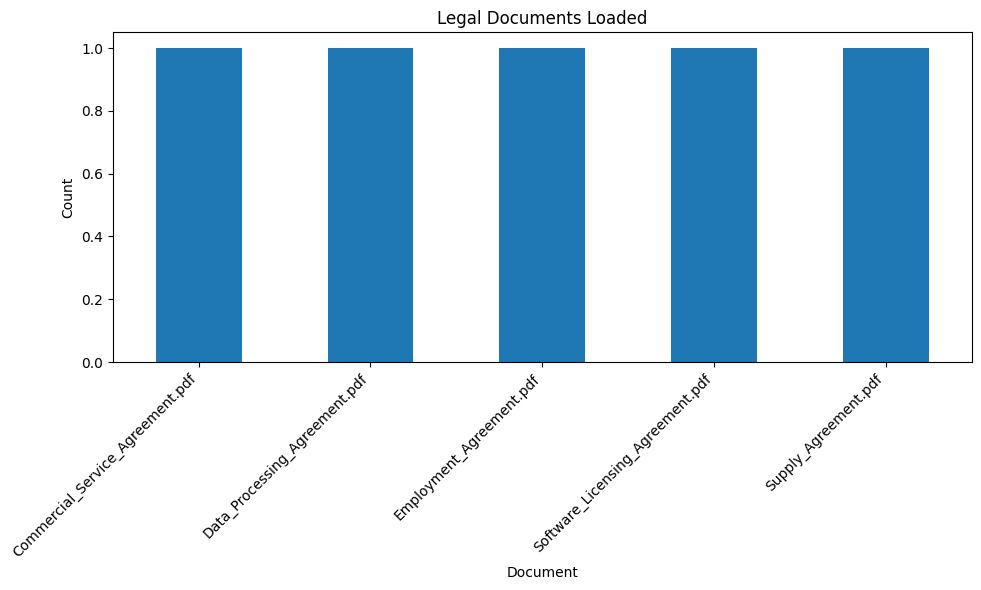

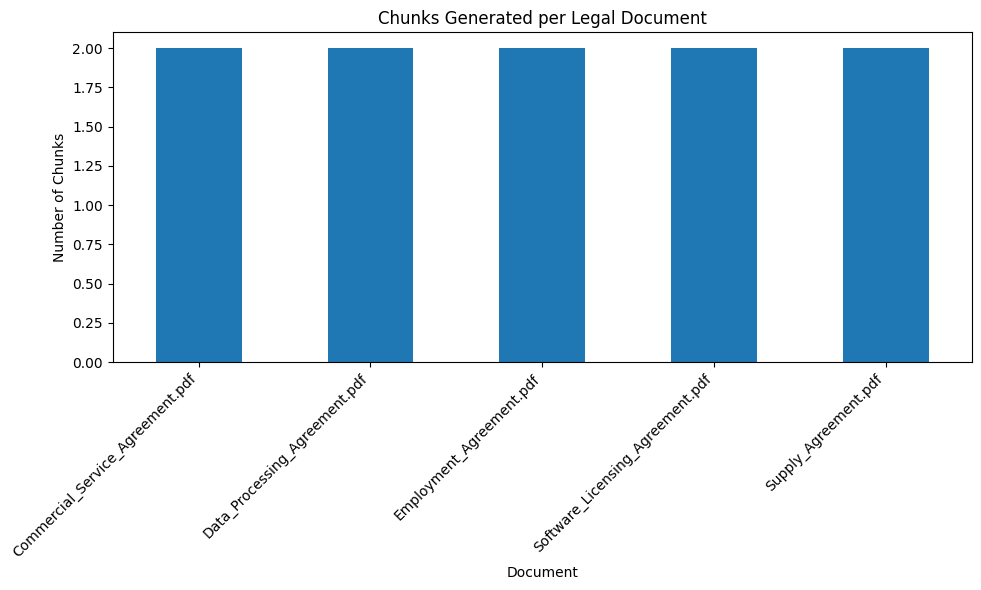

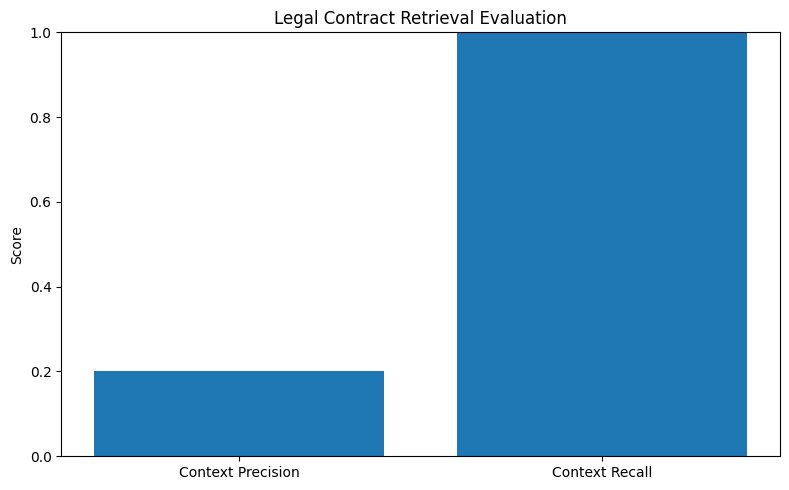


PS6 PROJECT COMPLETED
Legal documents: 5
Total chunks: 10
Context precision: 0.2
Context recall: 1.0

Project folder: /content/Legal_Contract_Hybrid_RAG

ZIP file: /content/Legal_Contract_Hybrid_RAG_PS6.zip

Generated files:
README.md
chunks/legal_embeddings.npy
chunks/legal_chunks.csv
chunks/legal_chunks.json
results/retrieval_evaluation.csv
results/evaluation_summary.json
results/document_metadata.csv
results/legal_qa_results.csv
results/legal_qa_results.json
data/raw/Data_Processing_Agreement.pdf
data/raw/Supply_Agreement.pdf
data/raw/Software_Licensing_Agreement.pdf
data/raw/Employment_Agreement.pdf
data/raw/Commercial_Service_Agreement.pdf
reports/PS6_Project_Report.md
graphs/document_count.png
graphs/retrieval_metrics.png
graphs/chunk_count.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PS6 pipeline finished.


In [1]:

# ================================================================
# PS6: PRODUCTION LEGAL CONTRACT Q&A
# Hybrid Search + Cross-Encoder Re-Ranking + Grounded QA
# ================================================================
# Run this complete cell in Google Colab.
#
# Input:
#   Legal contract PDF files
#
# Output:
#   /content/Legal_Contract_Hybrid_RAG/
#   /content/Legal_Contract_Hybrid_RAG_PS6.zip
#
# ================================================================

# ------------------------- 1. INSTALL ------------------------------

import sys
import subprocess

packages = [
    "pypdf",
    "sentence-transformers",
    "rank-bm25",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
    "tqdm"
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q"
] + packages)

print("All required packages installed.")


# ------------------------- 2. IMPORTS ------------------------------

import os
import re
import json
import time
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pypdf import PdfReader

from tqdm.auto import tqdm

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

from sentence_transformers import (
    SentenceTransformer,
    CrossEncoder
)

from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore")

np.random.seed(42)


# ------------------------- 3. DIRECTORIES --------------------------

OUTPUT_DIR = "/content/Legal_Contract_Hybrid_RAG"

DATA_DIR = os.path.join(
    OUTPUT_DIR,
    "data"
)

PDF_DIR = os.path.join(
    DATA_DIR,
    "raw"
)

CHUNK_DIR = os.path.join(
    OUTPUT_DIR,
    "chunks"
)

RESULT_DIR = os.path.join(
    OUTPUT_DIR,
    "results"
)

GRAPH_DIR = os.path.join(
    OUTPUT_DIR,
    "graphs"
)

REPORT_DIR = os.path.join(
    OUTPUT_DIR,
    "reports"
)

for directory in [
    OUTPUT_DIR,
    DATA_DIR,
    PDF_DIR,
    CHUNK_DIR,
    RESULT_DIR,
    GRAPH_DIR,
    REPORT_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("Project directories created.")


# ------------------------- 4. UPLOAD PDF FILES ---------------------

from google.colab import files

print("\nUpload your legal contract PDF files.")

uploaded_files = files.upload()

uploaded_pdf_names = []

for filename, file_bytes in uploaded_files.items():

    if filename.lower().endswith(".pdf"):

        output_path = os.path.join(
            PDF_DIR,
            os.path.basename(filename)
        )

        with open(output_path, "wb") as f:
            f.write(file_bytes)

        uploaded_pdf_names.append(
            os.path.basename(filename)
        )

        print("Saved:", filename)

print("\nUploaded PDF count:", len(uploaded_pdf_names))


# ------------------------- 5. PDF EXTRACTION -----------------------

def extract_pdf_text(pdf_path):

    try:

        reader = PdfReader(pdf_path)

        pages_text = []

        for page_number, page in enumerate(reader.pages, start=1):

            page_text = page.extract_text()

            if page_text:

                pages_text.append(
                    page_text.strip()
                )

        full_text = "\n\n".join(
            pages_text
        )

        return full_text

    except Exception as error:

        print(
            "PDF extraction error:",
            os.path.basename(pdf_path),
            str(error)
        )

        return ""


pdf_documents = []

for filename in sorted(
    os.listdir(PDF_DIR)
):

    if not filename.lower().endswith(".pdf"):
        continue

    pdf_path = os.path.join(
        PDF_DIR,
        filename
    )

    document_id = os.path.splitext(
        filename
    )[0]

    extracted_text = extract_pdf_text(
        pdf_path
    )

    if extracted_text.strip():

        document = {
            "document_id": document_id,
            "document_name": filename,
            "text": extracted_text,
            "source_type": "PDF"
        }

        pdf_documents.append(
            document
        )

        print(
            "PDF loaded:",
            filename
        )

    else:

        print(
            "WARNING: No extractable text:",
            filename
        )


print("\nTotal legal documents:", len(pdf_documents))


# ------------------------- 6. DOCUMENT METADATA ---------------------

metadata_records = []

for document in pdf_documents:

    metadata_records.append({

        "document_id": document["document_id"],

        "document_name": document["document_name"],

        "character_count": len(
            document["text"]
        ),

        "source_type": document["source_type"]

    })

metadata_df = pd.DataFrame(
    metadata_records
)

metadata_path = os.path.join(
    RESULT_DIR,
    "document_metadata.csv"
)

metadata_df.to_csv(
    metadata_path,
    index=False
)

print("\nDocument metadata:")

display(metadata_df)


# ------------------------- 7. TEXT CLEANING -------------------------

def clean_text(text):

    if not isinstance(text, str):
        return ""

    text = text.replace(
        "\x00",
        " "
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


for document in pdf_documents:

    document["text"] = clean_text(
        document["text"]
    )


# ------------------------- 8. LEGAL DOCUMENT CHUNKING -------------

def chunk_document(
    document,
    chunk_size=800,
    overlap=150
):
    """
    Split legal documents into overlapping chunks.

    This function avoids the previous malformed regex.

    Each chunk contains:
        chunk_id
        document_id
        document_name
        text
    """

    text = document.get(
        "text",
        ""
    )

    if not text.strip():
        return []

    # Safe clause-heading detection.
    # Uses non-capturing groups and a lookahead.
    clause_pattern = (
        r"(?m)"
        r"(?=^\s*(?:"
        r"ARTICLE\s+\d+"
        r"|SECTION\s+\d+"
        r"|\d+(?:\.\d+)*\.?"
        r")\s+)"
    )

    try:

        sections = re.split(
            clause_pattern,
            text
        )

    except re.error as error:

        print(
            "Clause splitting failed:",
            error
        )

        # Safe fallback: split by paragraphs.
        sections = re.split(
            r"\n\s*\n",
            text
        )

    chunks = []

    chunk_index = 0

    for section in sections:

        section = section.strip()

        if not section:
            continue

        # Short section.
        if len(section) <= chunk_size:

            chunks.append({

                "chunk_id": (
                    f"{document['document_id']}"
                    f"_chunk_{chunk_index}"
            ),

                "document_id": (
                    document["document_id"]
                ),

                "document_name": (
                    document["document_name"]
                ),

                "text": section

            })

            chunk_index += 1

            continue

        # Long section.
        start = 0

        while start < len(section):

            end = min(
                start + chunk_size,
                len(section)
            )

            chunk_text = section[
                start:end
            ].strip()

            if chunk_text:

                chunks.append({

                    "chunk_id": (
                        f"{document['document_id']}"
                        f"_chunk_{chunk_index}"
                ),

                    "document_id": (
                        document["document_id"]
                    ),

                    "document_name": (
                        document["document_name"]
                    ),

                    "text": chunk_text

                })

                chunk_index += 1

            if end >= len(section):
                break

            start = max(
                0,
                end - overlap
            )

    return chunks


# ------------------------- 9. GENERATE ALL CHUNKS -----------------

all_chunks = []

for document in pdf_documents:

    document_chunks = chunk_document(
        document,
        chunk_size=800,
        overlap=150
    )

    all_chunks.extend(
        document_chunks
    )

print("\nTotal legal documents:", len(pdf_documents))

print("Total chunks created:", len(all_chunks))


if not all_chunks:

    raise ValueError(
        "No chunks were created. "
        "Check whether your PDFs contain extractable text."
    )


# ------------------------- 10. SAVE CHUNKS -------------------------

chunks_df = pd.DataFrame(
    all_chunks
)

chunks_csv_path = os.path.join(
    CHUNK_DIR,
    "legal_chunks.csv"
)

chunks_df.to_csv(
    chunks_csv_path,
    index=False
)

chunks_json_path = os.path.join(
    CHUNK_DIR,
    "legal_chunks.json"
)

with open(
    chunks_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        all_chunks,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Chunks saved successfully.")


# ------------------------- 11. LOAD EMBEDDING MODEL ---------------

print("\nLoading Sentence Transformer model...")

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded.")


# ------------------------- 12. GENERATE EMBEDDINGS ----------------

chunk_texts = [
    chunk["text"]
    for chunk in all_chunks
]

embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

embeddings = np.asarray(
    embeddings,
    dtype=np.float32
)

print(
    "Embedding matrix shape:",
    embeddings.shape
)


# Save embeddings.
embedding_path = os.path.join(
    CHUNK_DIR,
    "legal_embeddings.npy"
)

np.save(
    embedding_path,
    embeddings
)


# ------------------------- 13. BM25 KEYWORD SEARCH ---------------

def tokenize_text(text):

    return re.findall(
        r"\b[a-zA-Z0-9]+\b",
        text.lower()
    )


tokenized_corpus = [
    tokenize_text(text)
    for text in chunk_texts
]

bm25 = BM25Okapi(
    tokenized_corpus
)

print("BM25 index created.")


# ------------------------- 14. DENSE SEARCH -----------------------

def dense_search(
    query,
    top_k=10
):

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    scores = np.dot(
        embeddings,
        query_embedding
    )

    top_indices = np.argsort(
        scores
    )[::-1][:top_k]

    results = []

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        results.append({

            "chunk": all_chunks[index],

            "score": float(
                scores[index]
            ),

            "rank": rank

        })

    return results


# ------------------------- 15. BM25 SEARCH -------------------------

def bm25_search(
    query,
    top_k=10
):

    query_tokens = tokenize_text(
        query
    )

    scores = bm25.get_scores(
        query_tokens
    )

    top_indices = np.argsort(
        scores
    )[::-1][:top_k]

    results = []

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        results.append({

            "chunk": all_chunks[index],

            "score": float(
                scores[index]
            ),

            "rank": rank

        })

    return results


# ------------------------- 16. RECIPROCAL RANK FUSION ------------

def reciprocal_rank_fusion(
    bm25_results,
    dense_results,
    k=60
):

    rrf_scores = {}

    chunk_lookup = {}

    # BM25 rankings.
    for result in bm25_results:

        chunk_id = result[
            "chunk"
        ]["chunk_id"]

        rank = result["rank"]

        rrf_scores[chunk_id] = (
            rrf_scores.get(
                chunk_id,
                0
            )
            + 1 / (k + rank)
        )

        chunk_lookup[chunk_id] = (
            result["chunk"]
        )

    # Dense rankings.
    for result in dense_results:

        chunk_id = result[
            "chunk"
        ]["chunk_id"]

        rank = result["rank"]

        rrf_scores[chunk_id] = (
            rrf_scores.get(
                chunk_id,
                0
            )
            + 1 / (k + rank)
        )

        chunk_lookup[chunk_id] = (
            result["chunk"]
        )

    sorted_chunks = sorted(
        rrf_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    fused_results = []

    for rank, (
        chunk_id,
        score
    ) in enumerate(
        sorted_chunks,
        start=1
    ):

        fused_results.append({

            "chunk": chunk_lookup[
                chunk_id
            ],

            "score": float(
                score
            ),

            "rank": rank

        })

    return fused_results


# ------------------------- 17. HYBRID SEARCH -----------------------

def hybrid_search(
    query,
    top_k=10,
    bm25_k=20,
    dense_k=20
):

    keyword_results = bm25_search(
        query,
        top_k=bm25_k
    )

    vector_results = dense_search(
        query,
        top_k=dense_k
    )

    fused_results = reciprocal_rank_fusion(
        keyword_results,
        vector_results
    )

    return fused_results[:top_k]


# ------------------------- 18. CROSS-ENCODER RE-RANKING ----------

print("\nLoading Cross-Encoder model...")

cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

print("Cross-Encoder loaded.")


def rerank_results(
    query,
    retrieved_results,
    top_k=5
):

    if not retrieved_results:
        return []

    pairs = []

    for result in retrieved_results:

        pairs.append((
            query,
            result["chunk"]["text"]
        ))

    scores = cross_encoder.predict(
        pairs,
        show_progress_bar=False
    )

    reranked_results = []

    for result, score in zip(
        retrieved_results,
        scores
    ):

        reranked_results.append({

            "chunk": result["chunk"],

            "score": float(
                score
            ),

            "rank": None

        })

    reranked_results.sort(
        key=lambda item: item["score"],
        reverse=True
    )

    for rank, result in enumerate(
        reranked_results,
        start=1
    ):

        result["rank"] = rank

    return reranked_results[:top_k]


# ------------------------- 19. CONTEXT COMPRESSION ---------------

def compress_context(
    reranked_results,
    max_chars=5000
):

    compressed_context = []

    total_chars = 0

    for result in reranked_results:

        chunk = result["chunk"]

        text = chunk["text"]

        remaining = (
            max_chars - total_chars
        )

        if remaining <= 0:
            break

        if len(text) > remaining:

            text = text[:remaining]

        compressed_context.append({

            "document_id": (
                chunk["document_id"]
            ),

            "document_name": (
                chunk["document_name"]
            ),

            "chunk_id": (
                chunk["chunk_id"]
            ),

            "text": text

        })

        total_chars += len(
            text
        )

    return compressed_context


# ------------------------- 20. OPTIONAL GEMINI ---------------------

# Gemini is optional.
# If no API key is provided, use extractive grounded answers.

USE_GEMINI = False

GEMINI_API_KEY = ""

try:

    from google.colab import userdata

    GEMINI_API_KEY = userdata.get(
        "GEMINI_API_KEY"
    )

except Exception:

    GEMINI_API_KEY = ""


if GEMINI_API_KEY:

    try:

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "google-genai"
        ])

        from google import genai

        gemini_client = genai.Client(
            api_key=GEMINI_API_KEY
        )

        USE_GEMINI = True

        print(
            "Gemini enabled."
        )

    except Exception as error:

        print(
            "Gemini unavailable:",
            error
        )

        USE_GEMINI = False

else:

    print(
        "Gemini API key not found. "
        "Using grounded extractive answers."
    )


# ------------------------- 21. ANSWER GENERATION -------------------

def extractive_answer(
    query,
    context
):

    if not context:

        return (
            "No relevant contract context was retrieved. "
            "The answer cannot be determined from the "
            "available documents."
        )

    query_tokens = set(
        tokenize_text(query)
    )

    scored_sentences = []

    for item in context:

        sentences = re.split(
            r"(?<=[.!?])\s+",
            item["text"]
        )

        for sentence in sentences:

            sentence = sentence.strip()

            if not sentence:
                continue

            sentence_tokens = set(
                tokenize_text(sentence)
            )

            overlap = len(
                query_tokens.intersection(
                    sentence_tokens
                )
            )

            if overlap > 0:

                scored_sentences.append({

                    "sentence": sentence,

                    "score": overlap,

                    "document_name": (
                        item["document_name"]
                    ),

                    "chunk_id": (
                        item["chunk_id"]
                    )

                })

    scored_sentences.sort(
        key=lambda item: item["score"],
        reverse=True
    )

    if not scored_sentences:

        best_item = context[0]

        return (
            "The retrieved contract context does not "
            "contain a sufficiently direct answer.\n\n"
            "Relevant context:\n"
            + best_item["text"]
            + "\n\nSource: "
            + best_item["document_name"]
            + " | Chunk: "
            + best_item["chunk_id"]
        )

    selected = scored_sentences[:5]

    answer_parts = []

    for item in selected:

        answer_parts.append(

            item["sentence"]

            + "\nSource: "
            + item["document_name"]

            + " | Chunk: "
            + item["chunk_id"]

        )

    return "\n\n".join(
        answer_parts
    )


def generate_answer(
    query,
    context
):

    if not context:

        return (
            "No relevant contract context was retrieved. "
            "Please check the uploaded documents."
        )

    if USE_GEMINI:

        context_text = "\n\n".join(

            "[Document: "
            + item["document_name"]
            + " | Chunk: "
            + item["chunk_id"]
            + "]\n"
            + item["text"]

            for item in context

        )

        prompt = f"""
You are a legal contract question-answering assistant.

Answer the user's question using ONLY the contract
context provided below.

Rules:
1. Do not invent legal terms.
2. Do not use external knowledge as contract facts.
3. If the answer is not present, say it is not found.
4. Cite the document name and chunk ID.
5. Distinguish contract wording from interpretation.
6. Do not claim to provide legal advice.

CONTRACT CONTEXT:
{context_text}

QUESTION:
{query}

Provide a concise answer with citations.
"""

        try:

            response = gemini_client.models.generate_content(
                model="gemini-2.5-flash",
                contents=prompt
            )

            answer = response.text

            if answer:

                return answer

        except Exception as error:

            print(
                "Gemini generation failed:",
                str(error)
            )

            print(
                "Falling back to extractive answer."
            )

    return extractive_answer(
        query,
        context
    )


# ------------------------- 22. COMPLETE RAG PIPELINE ---------------

def legal_contract_qa(
    query,
    retrieval_k=20,
    rerank_k=5,
    context_limit=5000
):

    start_time = time.time()

    # Hybrid retrieval.
    retrieved_results = hybrid_search(
        query,
        top_k=retrieval_k
    )

    # Cross-Encoder reranking.
    reranked_results = rerank_results_fn(
        query,
        retrieved_results,
        top_k=rerank_k
    )

    # Context compression.
    compressed_context = compress_context(
        reranked_results,
        max_chars=context_limit
    )

    # Answer generation.
    answer = generate_answer(
        query,
        compressed_context
    )

    elapsed_time = (
        time.time() - start_time
    )

    return {

        "query": query,

        "answer": answer,

        "retrieved_results": (
            retrieved_results
        ),

        "reranked_results": (
            reranked_results
        ),

        "context": (
            compressed_context
        ),

        "execution_time_seconds": (
            round(elapsed_time, 3)
        )

    }


# Preserve the function name without recursive shadowing.
rerank_results_fn = rerank_results


# ------------------------- 23. QUERY EXAMPLES -----------------------

query_examples = [

    "What are the payment terms?",

    "What happens if payment is late?",

    "What are the confidentiality obligations?",

    "How can the agreement be terminated?",

    "What law governs the contract?",

    "What are the liability limitations?",

    "What are the data security obligations?",

    "How quickly must a data breach be reported?",

    "What are the intellectual property rights?",

    "What are the delivery and inspection requirements?"

]


# ------------------------- 24. RUN EXAMPLE QUESTIONS ---------------

qa_results = []

print("\nRunning legal contract questions...\n")

for query in query_examples:

    print("=" * 80)

    print("QUESTION:", query)

    result = legal_contract_qa(
        query
    )

    print("\nANSWER:\n")

    print(result["answer"])

    print(
        "\nExecution time:",
        result["execution_time_seconds"],
        "seconds"
    )

    qa_results.append({

        "query": query,

        "answer": result["answer"],

        "execution_time_seconds": (
            result["execution_time_seconds"]
        )

    })


# ------------------------- 25. SAVE QA RESULTS ---------------------

qa_df = pd.DataFrame(
    qa_results
)

qa_csv_path = os.path.join(
    RESULT_DIR,
    "legal_qa_results.csv"
)

qa_df.to_csv(
    qa_csv_path,
    index=False
)

qa_json_path = os.path.join(
    RESULT_DIR,
    "legal_qa_results.json"
)

with open(
    qa_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        qa_results,
        f,
        indent=2,
        ensure_ascii=False
    )

print(
    "\nQA results saved."
)


# ------------------------- 26. RETRIEVAL EVALUATION ---------------

# Evaluation queries are automatically grounded in the
# uploaded filenames and document content.
#
# Expected document labels are actual uploaded document IDs.
# No hard-coded CONTRACT_001 IDs are used.

evaluation_queries = []

for document in pdf_documents:

    document_name = document[
        "document_name"
    ]

    document_id = document[
        "document_id"
    ]

    document_text = document[
        "text"
    ]

    # Extract a few sentences as document-grounded
    # evaluation query candidates.
    sentences = re.split(
        r"(?<=[.!?])\s+",
        document_text
    )

    candidates = []

    for sentence in sentences:

        sentence = sentence.strip()

        if len(sentence) < 35:
            continue

        if len(sentence) > 300:
            continue

        candidates.append(
            sentence
        )

    if candidates:

        evaluation_queries.append({

            "query": candidates[0],

            "expected_document": (
                document_id
            )

        })


# Limit evaluation runtime.
evaluation_queries = evaluation_queries[:20]

print(
    "\nEvaluation query count:",
    len(evaluation_queries)
)


# ------------------------- 27. METRIC FUNCTIONS ---------------------

def context_precision(
    retrieved_document_ids,
    expected_document
):

    if not retrieved_document_ids:
        return 0.0

    relevant_count = sum(

        1

        for document_id in (
            retrieved_document_ids
        )

        if document_id == expected_document

    )

    return (
        relevant_count
        / len(retrieved_document_ids)
    )


def context_recall(
    retrieved_document_ids,
    expected_document
):

    if not expected_document:
        return 0.0

    return float(

        expected_document
        in retrieved_document_ids

    )


# ------------------------- 28. RUN EVALUATION -----------------------

evaluation_records = []

for item in tqdm(
    evaluation_queries,
    desc="Evaluating retrieval"
):

    query = item["query"]

    expected_document = item[
        "expected_document"
    ]

    results = hybrid_search(
        query,
        top_k=10
    )

    retrieved_document_ids = [

        result["chunk"]["document_id"]

        for result in results

    ]

    precision = context_precision(
        retrieved_document_ids,
        expected_document
    )

    recall = context_recall(
        retrieved_document_ids,
        expected_document
    )

    evaluation_records.append({

        "query": query,

        "expected_document": (
            expected_document
        ),

        "context_precision": precision,

        "context_recall": recall

    })


evaluation_df = pd.DataFrame(
    evaluation_records
)

evaluation_csv_path = os.path.join(
    RESULT_DIR,
    "retrieval_evaluation.csv"
)

evaluation_df.to_csv(
    evaluation_csv_path,
    index=False
)


# ------------------------- 29. METRIC SUMMARY -----------------------

if not evaluation_df.empty:

    mean_precision = evaluation_df[
        "context_precision"
    ].mean()

    mean_recall = evaluation_df[
        "context_recall"
    ].mean()

else:

    mean_precision = 0.0

    mean_recall = 0.0


metric_summary = {

    "total_documents": len(
        pdf_documents
    ),

    "total_chunks": len(
        all_chunks
    ),

    "evaluation_queries": len(
        evaluation_df
    ),

    "context_precision": float(
        mean_precision
    ),

    "context_recall": float(
        mean_recall
    )

}

print("\n" + "=" * 80)

print("RETRIEVAL EVALUATION SUMMARY")

print("=" * 80)

for key, value in metric_summary.items():

    print(
        key,
        ":",
        value
    )


# ------------------------- 30. SAVE METRIC SUMMARY ------------------

summary_path = os.path.join(
    RESULT_DIR,
    "evaluation_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metric_summary,
        f,
        indent=2
    )


# ------------------------- 31. GRAPH: DOCUMENT COUNTS -------------

plt.figure(
    figsize=(10, 6)
)

document_counts = metadata_df[
    "document_name"
].value_counts()

document_counts.plot(
    kind="bar"
)

plt.title(
    "Legal Documents Loaded"
)

plt.xlabel(
    "Document"
)

plt.ylabel(
    "Count"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "document_count.png"
    ),
    dpi=300
)

plt.show()


# ------------------------- 32. GRAPH: CHUNK COUNTS ---------------

chunk_counts = chunks_df[
    "document_name"
].value_counts()

plt.figure(
    figsize=(10, 6)
)

chunk_counts.plot(
    kind="bar"
)

plt.title(
    "Chunks Generated per Legal Document"
)

plt.xlabel(
    "Document"
)

plt.ylabel(
    "Number of Chunks"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "chunk_count.png"
    ),
    dpi=300
)

plt.show()


# ------------------------- 33. GRAPH: RETRIEVAL METRICS ----------

if not evaluation_df.empty:

    plt.figure(
        figsize=(8, 5)
    )

    metric_values = [

        mean_precision,

        mean_recall

    ]

    metric_names = [

        "Context Precision",

        "Context Recall"

    ]

    plt.bar(
        metric_names,
        metric_values
    )

    plt.ylim(
        0,
        1
    )

    plt.title(
        "Legal Contract Retrieval Evaluation"
    )

    plt.ylabel(
        "Score"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            GRAPH_DIR,
            "retrieval_metrics.png"
        ),
        dpi=300
    )

    plt.show()


# ------------------------- 34. CREATE REPORT ------------------------

report_text = f"""
# PS6: Legal Contract Q&A with Hybrid Search

## Project Overview

This project implements a legal contract question-answering
system using hybrid retrieval and Cross-Encoder reranking.

## Documents

Total legal documents loaded: {len(pdf_documents)}

## Chunking

Total chunks created: {len(all_chunks)}

Chunk size: 800 characters

Overlap: 150 characters

## Retrieval Architecture

1. PDF text extraction
2. Document cleaning
3. Clause-aware chunking
4. Sentence Transformer embeddings
5. Dense vector retrieval
6. BM25 keyword retrieval
7. Reciprocal Rank Fusion
8. Cross-Encoder reranking
9. Context compression
10. Grounded answer generation

## Models

Embedding model:
sentence-transformers/all-MiniLM-L6-v2

Cross-Encoder:
cross-encoder/ms-marco-MiniLM-L-6-v2

## Evaluation

Evaluation queries: {len(evaluation_df)}

Context precision: {mean_precision:.4f}

Context recall: {mean_recall:.4f}

## Important Limitations

The generated answers are based on the uploaded contract text.

The system is not a substitute for legal advice.

Evaluation queries are generated from the uploaded documents.
This is a basic retrieval evaluation and does not represent
a manually validated legal benchmark.

PDFs containing scanned images without selectable text
require OCR before extraction.

## Output Files

- document_metadata.csv
- legal_chunks.csv
- legal_chunks.json
- legal_embeddings.npy
- legal_qa_results.csv
- legal_qa_results.json
- retrieval_evaluation.csv
- evaluation_summary.json
- graphs
"""

report_path = os.path.join(
    REPORT_DIR,
    "PS6_Project_Report.md"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        report_text
    )


# ------------------------- 35. CREATE README ------------------------

readme_text = """
# PS6: Legal Contract Q&A with Hybrid Search

## Project Description

A legal document question-answering system built using
hybrid retrieval and Cross-Encoder reranking.

## Technologies

- Python
- Google Colab
- PyPDF
- Sentence Transformers
- BM25
- Reciprocal Rank Fusion
- Cross-Encoder
- Gemini API (optional)
- Pandas
- NumPy
- Matplotlib

## Pipeline

PDF Upload
    |
PDF Text Extraction
    |
Text Cleaning
    |
Clause-Based Chunking
    |
Sentence Transformer Embeddings
    |
Dense Retrieval + BM25
    |
Reciprocal Rank Fusion
    |
Cross-Encoder Reranking
    |
Context Compression
    |
Grounded Legal Q&A
    |
Evaluation and Reports

## Models

Embedding:
sentence-transformers/all-MiniLM-L6-v2

Reranker:
cross-encoder/ms-marco-MiniLM-L-6-v2

## How to Run

1. Open Google Colab.
2. Create a Python notebook.
3. Paste the complete PS6 code.
4. Run the cell.
5. Upload legal contract PDFs.
6. Wait for model downloads and processing.
7. Review generated answers and evaluation.
8. Download the generated ZIP.

## Outputs

- Document metadata
- Legal document chunks
- Embedding matrix
- Question-answer results
- Retrieval evaluation
- Evaluation summary
- Graphs
- Project report

## Disclaimer

This is an educational project.
It does not provide professional legal advice.
"""

readme_path = os.path.join(
    OUTPUT_DIR,
    "README.md"
)

with open(
    readme_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        readme_text
    )


# ------------------------- 36. ZIP PROJECT --------------------------

zip_path = (
    "/content/"
    "Legal_Contract_Hybrid_RAG_PS6.zip"
)

if os.path.exists(
    zip_path
):

    os.remove(
        zip_path
    )

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, filenames in os.walk(
        OUTPUT_DIR
    ):

        for filename in filenames:

            file_path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                file_path,
                OUTPUT_DIR
            )

            zip_file.write(
                file_path,
                arcname=os.path.join(
                    "Legal_Contract_Hybrid_RAG",
                    relative_path
                )
            )


# ------------------------- 37. FINAL SUMMARY -----------------------

print("\n" + "=" * 80)

print("PS6 PROJECT COMPLETED")

print("=" * 80)

print(
    "Legal documents:",
    len(pdf_documents)
)

print(
    "Total chunks:",
    len(all_chunks)
)

print(
    "Context precision:",
    round(
        mean_precision,
        4
    )
)

print(
    "Context recall:",
    round(
        mean_recall,
        4
    )
)

print(
    "\nProject folder:",
    OUTPUT_DIR
)

print(
    "\nZIP file:",
    zip_path
)

print("\nGenerated files:")

for root, dirs, filenames in os.walk(
    OUTPUT_DIR
):

    for filename in filenames:

        print(
            os.path.relpath(
                os.path.join(
                    root,
                    filename
                ),
                OUTPUT_DIR
            )
        )


# ------------------------- 38. DOWNLOAD ZIP ------------------------

from google.colab import files

print("\nDownloading complete PS6 project ZIP...")

files.download(
    zip_path
)

print("\nPS6 pipeline finished.")


In [2]:


# ================================================================
# PS7: AUTONOMOUS FINANCIAL ANALYST AGENT
# Tool-Calling & Dynamic Execution
# Google Colab - Complete Project
#
# DOMAIN:
# Investment Banking & Wealth Management
#
# TOPICS:
# RAG vs AI Agents
# Tool Binding
# ReAct Framework
# SQL Query Tool
# Market RAG Tool
# Calculator Tool
# Agent Trace Logging
#
# FINAL OUTPUT:
# Complete project ZIP downloaded automatically
# ================================================================


# ================================================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# ================================================================

!pip install -q pypdf scikit-learn pandas


# ================================================================
# CELL 2: IMPORT LIBRARIES
# ================================================================

import os
import re
import json
import sqlite3
import ast
import operator
import zipfile
import shutil

from pathlib import Path
from datetime import datetime

import pandas as pd

from google.colab import files


print("=" * 70)
print("PS7 AUTONOMOUS FINANCIAL ANALYST AGENT")
print("=" * 70)


# ================================================================
# CELL 3: CREATE PROJECT DIRECTORIES
# ================================================================

PROJECT_DIR = Path(
    "/content/PS7_Autonomous_Financial_Analyst"
)

DATA_DIR = PROJECT_DIR / "data"

DATABASE_DIR = DATA_DIR / "database"

MARKET_REPORT_DIR = DATA_DIR / "market_reports"

OUTPUT_DIR = PROJECT_DIR / "outputs"

LOG_DIR = PROJECT_DIR / "logs"

DB_PATH = DATABASE_DIR / "financial_clients.db"

TRACE_PATH = LOG_DIR / "agent_trace.jsonl"

for directory in [
    PROJECT_DIR,
    DATA_DIR,
    DATABASE_DIR,
    MARKET_REPORT_DIR,
    OUTPUT_DIR,
    LOG_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# Clear previous execution trace
TRACE_PATH.write_text(
    "",
    encoding="utf-8"
)

print("\nProject directories created successfully.")

print("Project:", PROJECT_DIR)

print("Database:", DATABASE_DIR)

print("Market reports:", MARKET_REPORT_DIR)

print("Outputs:", OUTPUT_DIR)

print("Logs:", LOG_DIR)


# ================================================================
# CELL 4: CREATE SQLITE DATABASE
# ================================================================

print("\n" + "=" * 70)

print("CREATING FINANCIAL CLIENT DATABASE")

print("=" * 70)


def create_database():

    with sqlite3.connect(DB_PATH) as connection:

        connection.execute(
            """
            CREATE TABLE IF NOT EXISTS clients (

                client_id TEXT PRIMARY KEY,

                client_name TEXT,

                portfolio_balance REAL,

                annual_income REAL,

                tax_bracket REAL,

                risk_profile TEXT,

                currency TEXT

            )
            """
        )

        # Fictional educational client records

        clients = [

            (
                "CUST001",
                "Customer X",
                1250000,
                240000,
                0.32,
                "Moderate",
                "USD"
            ),

            (
                "CUST002",
                "Customer Y",
                875000,
                185000,
                0.24,
                "Conservative",
                "USD"
            ),

            (
                "CUST003",
                "Customer Z",
                2100000,
                420000,
                0.35,
                "Aggressive",
                "USD"
            )

        ]

        connection.executemany(

            """
            INSERT OR IGNORE INTO clients

            VALUES (?, ?, ?, ?, ?, ?, ?)

            """,

            clients

        )

    print("Database created successfully.")


create_database()


# ================================================================
# CELL 5: DISPLAY DATABASE
# ================================================================

print("\nFINANCIAL CLIENT RECORDS")

with sqlite3.connect(DB_PATH) as connection:

    client_dataframe = pd.read_sql_query(

        "SELECT * FROM clients",

        connection

    )

display(client_dataframe)


# ================================================================
# CELL 6: UPLOAD MARKET OUTLOOK PDF DOCUMENTS
# ================================================================

print("\n" + "=" * 70)

print("UPLOAD MARKET OUTLOOK DOCUMENTS")

print("=" * 70)

print(
    "Upload your market outlook PDF or TXT documents."
)

print(
    "You can upload multiple files."
)

print(
    "If you do not upload a file, the notebook creates "
    "a fictional educational market outlook sample."
)

uploaded_files = files.upload()


for filename, content in uploaded_files.items():

    file_path = MARKET_REPORT_DIR / Path(filename).name

    with open(
        file_path,
        "wb"
    ) as file:

        file.write(content)

    print("Uploaded:", file_path)


# Create fictional sample report only if no PDF/TXT exists

existing_reports = [

    file

    for file in MARKET_REPORT_DIR.iterdir()

    if file.suffix.lower() in [".pdf", ".txt"]

]


if not existing_reports:

    sample_report = MARKET_REPORT_DIR / "Q3_Market_Outlook.txt"

    sample_report.write_text(

        """
Q3 MARKET OUTLOOK
FICTIONAL EDUCATIONAL SAMPLE

Equity markets may experience volatility due to
macroeconomic announcements and changing economic conditions.

Interest rate expectations, inflation trends,
corporate earnings, and geopolitical events may
influence financial market performance.

Diversification can reduce concentration risk.
However, diversification does not eliminate
market risk.

Investors should consider liquidity needs,
financial objectives, and individual risk tolerance.

Tax outcomes depend on jurisdiction,
asset type, holding period, realized gains,
deductions, and individual circumstances.

Portfolio balance multiplied by a tax bracket
is not a tax liability calculation.

This sample report is fictional educational content.
It is not investment research or financial advice.

""",

        encoding="utf-8"

    )

    print(
        "\nSample market outlook created:",
        sample_report
    )


# ================================================================
# CELL 7: TRACE LOGGER
# ================================================================

print("\n" + "=" * 70)

print("INITIALIZING AGENT TRACE LOGGER")

print("=" * 70)


def trace(cycle, **kwargs):

    event = {

        "timestamp": datetime.now().isoformat(),

        "cycle": cycle,

        **kwargs

    }

    print(

        json.dumps(

            event,

            ensure_ascii=False

        )

    )

    TRACE_PATH.parent.mkdir(

        parents=True,

        exist_ok=True

    )

    with open(

        TRACE_PATH,

        "a",

        encoding="utf-8"

    ) as file:

        file.write(

            json.dumps(

                event,

                ensure_ascii=False

            ) + "\n"

        )


print("Trace logger initialized.")


# ================================================================
# CELL 8: CUSTOM TOOL 1 - SQL QUERY TOOL
# ================================================================

print("\n" + "=" * 70)

print("CUSTOM TOOL 1: SQL QUERY TOOL")

print("=" * 70)


def sql_query_tool(client_id: str) -> dict:

    """
    SQL Query Tool

    Purpose:
    Retrieve client financial information from SQLite.

    Args:
        client_id:
            Exact client identifier.

    Returns:
        Client portfolio information.
    """

    trace(

        "action",

        tool="sql_query_tool",

        arguments={

            "client_id": client_id

        }

    )

    with sqlite3.connect(DB_PATH) as connection:

        connection.row_factory = sqlite3.Row

        result = connection.execute(

            """

            SELECT

                client_id,

                client_name,

                portfolio_balance,

                annual_income,

                tax_bracket,

                risk_profile,

                currency

            FROM clients

            WHERE client_id = ?

            """,

            (client_id,)

        ).fetchone()


    if result:

        output = dict(result)

    else:

        output = {

            "error": "Client not found"

        }


    trace(

        "observation",

        tool="sql_query_tool",

        output=output

    )

    return output


print("SQL Query Tool created.")


# ================================================================
# CELL 9: CUSTOM TOOL 2 - MARKET RAG TOOL
# ================================================================

print("\n" + "=" * 70)

print("CUSTOM TOOL 2: MARKET RAG TOOL")

print("=" * 70)


def load_market_documents():

    """
    Load PDF and TXT documents from market report directory.
    """

    documents = []

    for file_path in MARKET_REPORT_DIR.iterdir():

        if file_path.suffix.lower() == ".txt":

            text = file_path.read_text(

                encoding="utf-8",

                errors="ignore"

            )

        elif file_path.suffix.lower() == ".pdf":

            from pypdf import PdfReader

            reader = PdfReader(

                str(file_path)

            )

            text = "\n".join(

                page.extract_text() or ""

                for page in reader.pages

            )

        else:

            continue


        # Split documents into passages

        chunks = re.split(

            r"\n\s*\n",

            text

        )

        for chunk_id, chunk in enumerate(chunks):

            chunk = chunk.strip()

            if chunk:

                documents.append({

                    "source": file_path.name,

                    "chunk": chunk_id,

                    "text": chunk

                })

    return documents


def market_rag_tool(

    query: str,

    top_k: int = 3

) -> dict:

    """
    Market RAG Tool

    Purpose:
    Retrieve relevant passages from market outlook
    documents using TF-IDF and cosine similarity.

    Args:
        query:
            Financial market question.

        top_k:
            Number of passages to retrieve.

    Returns:
        Retrieved passages and source information.
    """

    trace(

        "action",

        tool="market_rag_tool",

        arguments={

            "query": query,

            "top_k": top_k

        }

    )

    documents = load_market_documents()


    if not documents:

        output = {

            "passages": [],

            "warning": "No market documents found."

        }

        trace(

            "observation",

            tool="market_rag_tool",

            output=output

        )

        return output


    from sklearn.feature_extraction.text import TfidfVectorizer

    from sklearn.metrics.pairwise import cosine_similarity


    vectorizer = TfidfVectorizer(

        stop_words="english"

    )


    document_texts = [

        document["text"]

        for document in documents

    ]


    all_texts = document_texts + [query]


    matrix = vectorizer.fit_transform(

        all_texts

    )


    similarity_scores = cosine_similarity(

        matrix[-1],

        matrix[:-1]

    ).flatten()


    ranked_indices = similarity_scores.argsort()[::-1]


    selected_indices = ranked_indices[:top_k]


    retrieved_passages = []


    for index in selected_indices:

        score = similarity_scores[index]

        if score > 0:

            retrieved_passages.append({

                "source": documents[index]["source"],

                "chunk": documents[index]["chunk"],

                "text": documents[index]["text"],

                "score": round(

                    float(score),

                    4

                )

            })


    output = {

        "passages": retrieved_passages

    }


    trace(

        "observation",

        tool="market_rag_tool",

        output=output

    )


    return output


print("Market RAG Tool created.")


# ================================================================
# CELL 10: CUSTOM TOOL 3 - SAFE CALCULATOR
# ================================================================

print("\n" + "=" * 70)

print("CUSTOM TOOL 3: SAFE CALCULATOR")

print("=" * 70)


# Allowed arithmetic operations

ALLOWED_OPERATIONS = {

    ast.Add: operator.add,

    ast.Sub: operator.sub,

    ast.Mult: operator.mul,

    ast.Div: operator.truediv,

    ast.Pow: operator.pow,

    ast.USub: operator.neg,

    ast.UAdd: operator.pos,

    ast.Mod: operator.mod

}


def safe_calculate(node):

    """
    Safely evaluate arithmetic expressions.

    Arbitrary Python execution is not allowed.
    """

    if isinstance(

        node,

        ast.Constant

    ):

        if type(node.value) in (

            int,

            float

        ):

            return node.value


    if isinstance(

        node,

        ast.BinOp

    ):

        if type(node.op) in ALLOWED_OPERATIONS:

            left = safe_calculate(

                node.left

            )

            right = safe_calculate(

                node.right

            )

            # Restrict exponent size

            if isinstance(

                node.op,

                ast.Pow

            ):

                if abs(right) > 8:

                    raise ValueError(

                        "Exponent limit exceeded"

                    )


            return ALLOWED_OPERATIONS[

                type(node.op)

            ](

                left,

                right

            )


    if isinstance(

        node,

        ast.UnaryOp

    ):

        if type(node.op) in ALLOWED_OPERATIONS:

            return ALLOWED_OPERATIONS[

                type(node.op)

            ](

                safe_calculate(

                    node.operand

                )

            )


    raise ValueError(

        "Only numeric arithmetic is allowed"

    )


def calculator_tool(

    expression: str

) -> dict:

    """
    Calculator Tool

    Purpose:
    Perform safe arithmetic calculations.

    Args:
        expression:
            Arithmetic expression.

    Returns:
        Calculation result.
    """

    trace(

        "action",

        tool="calculator_tool",

        arguments={

            "expression": expression

        }

    )

    try:

        parsed_expression = ast.parse(

            expression,

            mode="eval"

        )

        result = safe_calculate(

            parsed_expression.body

        )

        output = {

            "expression": expression,

            "result": result

        }

    except Exception as error:

        output = {

            "expression": expression,

            "error": str(error)

        }


    trace(

        "observation",

        tool="calculator_tool",

        output=output

    )


    return output


print("Calculator Tool created.")


# ================================================================
# CELL 11: CLIENT IDENTIFICATION
# ================================================================

print("\n" + "=" * 70)

print("CLIENT IDENTIFICATION")

print("=" * 70)


def identify_client(question):

    """
    Identify client ID from user query.
    """

    match = re.search(

        r"\bCUST\d{3,}\b",

        question.upper()

    )

    if match:

        return match.group(0)


    question_lower = question.lower()


    if "customer x" in question_lower:

        return "CUST001"


    if "customer y" in question_lower:

        return "CUST002"


    if "customer z" in question_lower:

        return "CUST003"


    # Default educational client

    return "CUST001"


print("Client identification function created.")


# ================================================================
# CELL 12: REACT AGENT CONTROLLER
# ================================================================

print("\n" + "=" * 70)

print("REACT AGENT CONTROLLER")

print("=" * 70)


def run_react_agent(question):

    """
    Autonomous Financial Analyst Agent

    Implements a transparent ReAct-style workflow:

    Thought
        Identify required information.

    Action
        Call SQL Query Tool.

    Observation
        Receive client portfolio information.

    Action
        Call Market RAG Tool.

    Observation
        Receive market evidence.

    Action
        Call Calculator Tool.

    Observation
        Receive calculation result.

    Final
        Generate financial analyst report.
    """

    print("\n")

    trace(

        "thought",

        content=(

            "Analyze financial question. "

            "Retrieve client data from SQL. "

            "Retrieve market evidence using RAG. "

            "Calculate requested estimate. "

            "Synthesize final response."

        )

    )


    # ------------------------------------------------------------
    # STEP 1: IDENTIFY CLIENT
    # ------------------------------------------------------------

    client_id = identify_client(

        question

    )


    print(

        "\nIdentified client:",

        client_id

    )


    # ------------------------------------------------------------
    # STEP 2: ACTION - SQL TOOL
    # ------------------------------------------------------------

    print("\nACTION: SQL QUERY TOOL")

    client_data = sql_query_tool(

        client_id

    )


    if "error" in client_data:

        final_answer = (

            "Client information could not be retrieved."

        )

        trace(

            "final",

            answer=final_answer

        )

        return final_answer


    # ------------------------------------------------------------
    # STEP 3: ACTION - MARKET RAG TOOL
    # ------------------------------------------------------------

    print("\nACTION: MARKET RAG TOOL")


    market_results = market_rag_tool(

        question,

        top_k=3

    )


    # ------------------------------------------------------------
    # STEP 4: ACTION - CALCULATOR TOOL
    # ------------------------------------------------------------

    print("\nACTION: CALCULATOR TOOL")


    portfolio_balance = float(

        client_data["portfolio_balance"]

    )


    tax_bracket = float(

        client_data["tax_bracket"]

    )


    # Educational arithmetic proxy only

    calculation_expression = (

        f"{portfolio_balance} * {tax_bracket}"

    )


    trace(

        "thought",

        content=(

            "Calculate portfolio balance multiplied "

            "by tax bracket as an illustrative "

            "arithmetic proxy. This is not "

            "a tax liability calculation."

        )

    )


    calculation_result = calculator_tool(

        calculation_expression

    )


    # ------------------------------------------------------------
    # STEP 5: PROCESS MARKET EVIDENCE
    # ------------------------------------------------------------

    passages = market_results.get(

        "passages",

        []

    )


    if passages:

        evidence_text = "\n".join(

            [

                (

                    f"- Source: {passage['source']} | "

                    f"Chunk: {passage['chunk']} | "

                    f"Similarity: {passage['score']}\n"

                    f"  {passage['text']}"

                )

                for passage in passages

            ]

        )

    else:

        evidence_text = market_results.get(

            "warning",

            "No market evidence retrieved."

        )


    # ------------------------------------------------------------
    # STEP 6: SYNTHESIZE FINAL REPORT
    # ------------------------------------------------------------

    calculated_amount = calculation_result.get(

        "result",

        0

    )


    final_answer = f"""

# AUTONOMOUS FINANCIAL ANALYST REPORT

## Client Information

Client Name: {client_data['client_name']}

Client ID: {client_data['client_id']}

Currency: {client_data['currency']}


## Portfolio Analysis

Current Portfolio Balance:

{client_data['currency']} {client_data['portfolio_balance']:,.2f}


Annual Income:

{client_data['currency']} {client_data['annual_income']:,.2f}


Tax Bracket:

{client_data['tax_bracket']:.0%}


Risk Profile:

{client_data['risk_profile']}


## Illustrative Calculation

Portfolio Balance × Tax Bracket:

{client_data['currency']} {calculated_amount:,.2f}


Calculation:

{calculation_expression}


## Market Outlook Evidence

{evidence_text}


## Agent Execution Summary

1. Client identified using the user query.

2. SQL Query Tool retrieved portfolio information.

3. Market RAG Tool retrieved relevant market passages.

4. Calculator Tool executed arithmetic.

5. Agent synthesized the final report.


## Important Limitations

This is a fictional educational project.

Portfolio balance multiplied by a tax bracket is NOT
a projected tax liability.

Actual tax analysis requires:

- Tax jurisdiction
- Financial holdings
- Cost basis
- Realized gains
- Unrealized gains
- Applicable deductions
- Applicable tax rules

Market retrieval is based only on uploaded reports.

This report is not investment, tax, or legal advice.

"""


    trace(

        "final",

        answer=final_answer

    )


    return final_answer


print("ReAct Agent Controller created.")


# ================================================================
# CELL 13: EXECUTE FINANCIAL ANALYST QUERY
# ================================================================

print("\n")

print("=" * 70)

print("EXECUTING FINANCIAL ANALYST AGENT")

print("=" * 70)


USER_QUESTION = (

    "Compare Customer X's current portfolio balance "

    "against our Q3 market outlook PDF and "

    "calculate projected tax risk."

)


print("\nUSER QUESTION:")

print(USER_QUESTION)


FINAL_REPORT = run_react_agent(

    USER_QUESTION

)


print("\n")

print("=" * 70)

print("FINAL FINANCIAL ANALYST OUTPUT")

print("=" * 70)


print(FINAL_REPORT)


# ================================================================
# CELL 14: EVALUATION
# ================================================================

print("\n")

print("=" * 70)

print("AGENT EVALUATION")

print("=" * 70)


evaluation_questions = [

    "Compare Customer X portfolio with Q3 market outlook",

    "Compare CUST002 portfolio balance and market risks",

    "Review Customer Z portfolio and market outlook"

]


evaluation_results = []


for question in evaluation_questions:

    print("\n")

    print("-" * 70)

    print("QUESTION:", question)

    print("-" * 70)


    answer = run_react_agent(

        question

    )


    evaluation_results.append({

        "question": question,

        "answer": answer

    })


print("\nEvaluation completed.")

print(

    "Total evaluation queries:",

    len(evaluation_results)

)


# ================================================================
# CELL 15: SAVE FINAL REPORT AND EVALUATION
# ================================================================

print("\n")

print("=" * 70)

print("SAVING PROJECT OUTPUTS")

print("=" * 70)


REPORT_PATH = OUTPUT_DIR / "financial_analyst_report.md"


EVALUATION_PATH = OUTPUT_DIR / "evaluation_results.json"


TRACE_OUTPUT_PATH = OUTPUT_DIR / "agent_trace.jsonl"


# Save final report

REPORT_PATH.write_text(

    FINAL_REPORT,

    encoding="utf-8"

)


# Save evaluation

EVALUATION_PATH.write_text(

    json.dumps(

        evaluation_results,

        indent=4,

        ensure_ascii=False

    ),

    encoding="utf-8"

)


# Save trace

shutil.copy(

    TRACE_PATH,

    TRACE_OUTPUT_PATH

)


print("Final report saved:", REPORT_PATH)

print("Evaluation saved:", EVALUATION_PATH)

print("Trace saved:", TRACE_OUTPUT_PATH)


# ================================================================
# CELL 16: GENERATE README
# ================================================================

print("\n")

print("=" * 70)

print("GENERATING README")

print("=" * 70)


README_CONTENT = """

# PS7: Autonomous Financial Analyst Agent

## Project Domain

Investment Banking & Wealth Management

## Problem Statement

Develop an autonomous financial analyst agent capable of
answering multi-part financial questions using:

- SQL database queries
- Market document retrieval
- Calculator tools
- ReAct-style reasoning and tool execution

## Architecture

User Question
     |
     v
ReAct Agent Controller
     |
     +---- SQL Query Tool
     |
     +---- Market RAG Tool
     |
     +---- Calculator Tool
     |
     v
Financial Analyst Report

## Tools Implemented

### SQL Query Tool

Retrieves client portfolio balances, income,
tax bracket, risk profile, and currency.

### Market RAG Tool

Retrieves relevant passages from uploaded
market outlook PDF/TXT documents.

### Calculator Tool

Performs restricted numeric arithmetic
using an AST allowlist.

## Agent Framework

The project demonstrates a transparent
ReAct-style workflow:

Thought
Action
Observation
Action
Observation
Final Answer

## Database

SQLite

## Retrieval

TF-IDF Vectorization

Cosine Similarity

## Trace Logging

JSON Lines format

## Output Files

- financial_analyst_report.md
- evaluation_results.json
- agent_trace.jsonl

## Dataset

All included client information is fictional.

## Disclaimer

Portfolio balance multiplied by tax bracket
is not a tax liability estimate.

This project is an educational demonstration
and is not investment, tax, or legal advice.

"""


README_PATH = PROJECT_DIR / "README.md"


README_PATH.write_text(

    README_CONTENT,

    encoding="utf-8"

)


print("README generated.")


# ================================================================
# CELL 17: GENERATE REQUIREMENTS FILE
# ================================================================

print("\n")

print("=" * 70)

print("GENERATING REQUIREMENTS")

print("=" * 70)


requirements_content = """

pypdf

scikit-learn

pandas

"""


REQUIREMENTS_PATH = PROJECT_DIR / "requirements.txt"


REQUIREMENTS_PATH.write_text(

    requirements_content.strip(),

    encoding="utf-8"

)


print("Requirements file generated.")


# ================================================================
# CELL 18: FINAL PROJECT STRUCTURE
# ================================================================

print("\n")

print("=" * 70)

print("FINAL PROJECT STRUCTURE")

print("=" * 70)


for root, directories, filenames in os.walk(

    PROJECT_DIR

):

    level = root.replace(

        str(PROJECT_DIR),

        ""

    ).count(os.sep)


    indent = " " * 4 * level


    print(

        f"{indent}{Path(root).name}/"

    )


    for filename in filenames:

        print(

            f"{indent}    {filename}"

        )


# ================================================================
# CELL 19: CREATE COMPLETE PROJECT ZIP
# ================================================================

print("\n")

print("=" * 70)

print("CREATING COMPLETE PROJECT ZIP")

print("=" * 70)


ZIP_PATH = Path(

    "/content/PS7_Autonomous_Financial_Analyst.zip"

)


# Remove previous ZIP if present

if ZIP_PATH.exists():

    ZIP_PATH.unlink()


with zipfile.ZipFile(

    ZIP_PATH,

    "w",

    zipfile.ZIP_DEFLATED

) as zip_file:


    for file_path in PROJECT_DIR.rglob("*"):

        if file_path.is_file():

            archive_name = (

                Path("PS7_Autonomous_Financial_Analyst")

                / file_path.relative_to(PROJECT_DIR)

            )


            zip_file.write(

                file_path,

                archive_name

            )


print("\nZIP CREATED SUCCESSFULLY")


print("ZIP LOCATION:")

print(ZIP_PATH)


print("\nZIP SIZE:")

print(

    round(

        ZIP_PATH.stat().st_size / 1024,

        2

    ),

    "KB"

)


# ================================================================
# CELL 20: DOWNLOAD COMPLETE PROJECT ZIP
# ================================================================

print("\n")

print("=" * 70)

print("DOWNLOADING COMPLETE PS7 PROJECT")

print("=" * 70)


files.download(

    str(ZIP_PATH)

)


print("\n")

print("=" * 70)

print("PS7 PROJECT COMPLETED")

print("=" * 70)

print("\nAll tasks completed.")

print("Database created.")

print("Market RAG executed.")

print("SQL tool executed.")

print("Calculator executed.")

print("ReAct agent executed.")

print("Financial analyst report generated.")

print("Evaluation completed.")

print("Trace logs generated.")

print("Complete project ZIP downloaded.")

print("\nTHANK YOU")


PS7 AUTONOMOUS FINANCIAL ANALYST AGENT

Project directories created successfully.
Project: /content/PS7_Autonomous_Financial_Analyst
Database: /content/PS7_Autonomous_Financial_Analyst/data/database
Market reports: /content/PS7_Autonomous_Financial_Analyst/data/market_reports
Outputs: /content/PS7_Autonomous_Financial_Analyst/outputs
Logs: /content/PS7_Autonomous_Financial_Analyst/logs

CREATING FINANCIAL CLIENT DATABASE
Database created successfully.

FINANCIAL CLIENT RECORDS


,client_id,client_name,portfolio_balance,annual_income,tax_bracket,risk_profile,currency
0,CUST001,Customer X,1250000.0,240000.0,0.32,Moderate,USD
1,CUST002,Customer Y,875000.0,185000.0,0.24,Conservative,USD
2,CUST003,Customer Z,2100000.0,420000.0,0.35,Aggressive,USD



UPLOAD MARKET OUTLOOK DOCUMENTS
Upload your market outlook PDF or TXT documents.
You can upload multiple files.
If you do not upload a file, the notebook creates a fictional educational market outlook sample.


Saving PS7_Q3_Market_Outlook.pdf to PS7_Q3_Market_Outlook.pdf
Uploaded: /content/PS7_Autonomous_Financial_Analyst/data/market_reports/PS7_Q3_Market_Outlook.pdf

INITIALIZING AGENT TRACE LOGGER
Trace logger initialized.

CUSTOM TOOL 1: SQL QUERY TOOL
SQL Query Tool created.

CUSTOM TOOL 2: MARKET RAG TOOL
Market RAG Tool created.

CUSTOM TOOL 3: SAFE CALCULATOR
Calculator Tool created.

CLIENT IDENTIFICATION
Client identification function created.

REACT AGENT CONTROLLER
ReAct Agent Controller created.


EXECUTING FINANCIAL ANALYST AGENT

USER QUESTION:
Compare Customer X's current portfolio balance against our Q3 market outlook PDF and calculate projected tax risk.


{"timestamp": "2026-10-26T17:33:38.833395", "cycle": "thought", "content": "Analyze financial question. Retrieve client data from SQL. Retrieve market evidence using RAG. Calculate requested estimate. Synthesize final response."}

Identified client: CUST001

ACTION: SQL QUERY TOOL
{"timestamp": "2026-10-26T17:33:38.834256"

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



PS7 PROJECT COMPLETED

All tasks completed.
Database created.
Market RAG executed.
SQL tool executed.
Calculator executed.
ReAct agent executed.
Financial analyst report generated.
Evaluation completed.
Trace logs generated.
Complete project ZIP downloaded.

THANK YOU


In [3]:

# ================================================================
# PS8: COLLABORATIVE MULTI-AGENT DEVSECOPS
# Complete Google Colab Implementation
# LangGraph + OWASP RAG + Security Scanner + Remediation + QA
# Automatic ZIP Download
# ================================================================

import os
import sys
import json
import re
import time
import subprocess
import zipfile
from pathlib import Path

# -------------------- INSTALL --------------------

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "langgraph", "scikit-learn"
])

from typing import TypedDict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from langgraph.graph import StateGraph, END

# -------------------- PROJECT STRUCTURE --------------------

ROOT = Path("/content/PS8_MultiAgent_DevSecOps")
SRC = ROOT / "source"
OUT = ROOT / "outputs"
LOG = ROOT / "logs"
REPORT = ROOT / "reports"
KB = ROOT / "knowledge_base"
TESTS = ROOT / "tests"

for folder in [SRC, OUT, LOG, REPORT, KB, TESTS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory created:", ROOT)

# -------------------- VULNERABLE APPLICATION --------------------

VULNERABLE_CODE = r'''
import sqlite3
import subprocess

def get_user(username):
    conn = sqlite3.connect("users.db")
    query = "SELECT * FROM users WHERE username = '" + username + "'"
    cursor = conn.cursor()
    cursor.execute(query)
    result = cursor.fetchone()
    conn.close()
    return result

def execute_command(filename):
    command = "cat " + filename
    result = subprocess.run(
        command,
        shell=True,
        capture_output=True,
        text=True
    )
    return result.stdout

def authenticate(password):
    stored_password = "admin123"
    if password == stored_password:
        return True
    return False
'''

(SRC / "vulnerable_app.py").write_text(
    VULNERABLE_CODE, encoding="utf-8"
)

print("Vulnerable application created.")

# -------------------- OWASP KNOWLEDGE BASE --------------------

OWASP_DOCS = [
    {
        "id": "OWASP-A03-SQLI",
        "title": "SQL Injection Prevention",
        "text": """
        SQL injection occurs when untrusted input is concatenated
        into SQL statements. Use parameterized queries and
        prepared statements. Never construct SQL using
        user-controlled string concatenation.
        """
    },
    {
        "id": "OWASP-CMDI",
        "title": "OS Command Injection Defense",
        "text": """
        Avoid shell=True and shell command strings.
        Prefer subprocess argument lists with shell=False.
        Validate filenames and restrict file paths
        to an allowed directory.
        """
    },
    {
        "id": "OWASP-SECRETS",
        "title": "Secrets Management",
        "text": """
        Never hardcode passwords, API keys, or secrets.
        Load credentials from environment variables
        or a managed secret store.
        Rotate exposed credentials.
        """
    },
    {
        "id": "OWASP-PASSWORD",
        "title": "Password Storage",
        "text": """
        Never store passwords in plaintext.
        Use password hashing such as Argon2id,
        bcrypt, or scrypt with appropriate salts
        and work factors.
        """
    },
    {
        "id": "OWASP-TEST",
        "title": "Security Testing",
        "text": """
        Validate fixes using syntax checks,
        unit tests, and regression tests.
        Static checks are not actual test execution.
        Untrusted code requires sandbox isolation,
        resource limits, and restricted network access.
        """
    }
]

(KB / "owasp_knowledge.json").write_text(
    json.dumps(OWASP_DOCS, indent=2),
    encoding="utf-8"
)

# -------------------- RAG RETRIEVAL --------------------

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

kb_matrix = vectorizer.fit_transform([
    doc["title"] + " " + doc["text"]
    for doc in OWASP_DOCS
])

def retrieve_owasp(query, top_k=3):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, kb_matrix)[0]
    indices = scores.argsort()[::-1][:top_k]

    return [
        {
            **OWASP_DOCS[i],
            "score": float(scores[i])
        }
        for i in indices
        if scores[i] > 0
    ]

# -------------------- SHARED STATE --------------------

class AgentState(TypedDict, total=False):
    original_code: str
    current_code: str
    findings: list
    retrieved_docs: list
    patches: list
    messages: list
    qa_results: list
    iteration: int
    max_iterations: int
    tests_passed: bool

# -------------------- AUDIT LOG --------------------

AUDIT = []

def audit(agent, event, details):
    record = {
        "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"),
        "agent": agent,
        "event": event,
        "details": details
    }

    AUDIT.append(record)

    (LOG / "security_audit_log.json").write_text(
        json.dumps(AUDIT, indent=2),
        encoding="utf-8"
    )

    with open(
        LOG / "agent_trace.jsonl",
        "a",
        encoding="utf-8"
    ) as file:
        file.write(json.dumps(record) + "\n")

# ================================================================
# AGENT 1: SECURITY SCANNER
# ================================================================

def scanner_agent(state: AgentState):
    print("\nSECURITY SCANNER AGENT")

    code = state["current_code"]
    findings = []
    retrieved = []

    checks = [
        (
            "SEC-001", "SQL_INJECTION", "HIGH",
            r"execute\s*\(\s*query\s*\)|SELECT.*\+\s*username",
            "SQL injection risk"
        ),
        (
            "SEC-002", "COMMAND_INJECTION", "HIGH",
            r"shell\s*=\s*True|command\s*=\s*['\"][^'\"]*\+",
            "Unsafe shell execution"
        ),
        (
            "SEC-003", "HARDCODED_SECRET", "HIGH",
            r"stored_password\s*=\s*['\"][^'\"]+['\"]",
            "Hardcoded credential"
        ),
        (
            "SEC-004", "PLAINTEXT_PASSWORD", "HIGH",
            r"password\s*==\s*stored_password",
            "Plaintext password comparison"
        )
    ]

    for fid, kind, severity, pattern, description in checks:
        if re.search(pattern, code, re.I | re.S):
            docs = retrieve_owasp(kind + " " + description)

            retrieved.extend(docs)

            findings.append({
                "id": fid,
                "type": kind,
                "severity": severity,
                "description": description,
                "owasp_refs": [d["id"] for d in docs]
            })

    unique_docs = {
        doc["id"]: doc for doc in retrieved
    }

    retrieved = list(unique_docs.values())

    state["findings"] = findings
    state["retrieved_docs"] = retrieved

    state.setdefault("messages", []).append({
        "from": "SecurityScannerAgent",
        "to": "RemediationAgent",
        "type": "SCAN_RESULT",
        "findings": findings,
        "retrieved_docs": [d["id"] for d in retrieved]
    })

    audit("SecurityScannerAgent", "scan_completed", {
        "findings": findings,
        "retrieved_documents": [d["id"] for d in retrieved]
    })

    print("Findings:", len(findings))

    for finding in findings:
        print(finding["id"], finding["type"], finding["severity"])

    return state

# ================================================================
# AGENT 2: REMEDIATION AGENT
# ================================================================

def remediation_agent(state: AgentState):
    print("\nREMEDIATION AGENT")

    code = state["current_code"]
    findings = state.get("findings", [])
    types = [f["type"] for f in findings]
    patches = []

    # SQL INJECTION FIX

    if "SQL_INJECTION" in types:

        old = '''    query = "SELECT * FROM users WHERE username = '" + username + "'"'''

        new = '''    query = "SELECT * FROM users WHERE username = ?"'''

        if old in code:
            code = code.replace(old, new)

            code = code.replace(
                "cursor.execute(query)",
                "cursor.execute(query, (username,))"
            )

            patches.append({
                "id": "PATCH-001",
                "finding": "SEC-001",
                "change": "Parameterized SQL"
            })

    # COMMAND INJECTION FIX
    # Exact complete function replacement.
    # This fixes the previously failing remediation.

    if "COMMAND_INJECTION" in types:

        old_function = '''def execute_command(filename):
    command = "cat " + filename
    result = subprocess.run(
        command,
        shell=True,
        capture_output=True,
        text=True
    )
    return result.stdout'''

        new_function = '''def execute_command(filename):
    from pathlib import Path

    allowed_directory = Path("safe_files").resolve()
    requested_file = (
        allowed_directory / filename
    ).resolve()

    if not requested_file.is_relative_to(
        allowed_directory
    ):
        raise ValueError("Invalid file path")

    if not requested_file.is_file():
        raise FileNotFoundError("File not found")

    result = subprocess.run(
        ["cat", str(requested_file)],
        shell=False,
        capture_output=True,
        text=True,
        check=True,
        timeout=10
    )

    return result.stdout'''

        if old_function in code:

            code = code.replace(
                old_function,
                new_function
            )

            patches.append({
                "id": "PATCH-002",
                "finding": "SEC-002",
                "change": "Safe subprocess and path validation"
            })

    # HARDCODED SECRET FIX

    if "HARDCODED_SECRET" in types:

        code = code.replace(
            '    stored_password = "admin123"',
            '    stored_password = os.environ.get("ADMIN_PASSWORD", "")'
        )

        if "import os" not in code:
            code = "import os\n" + code

        patches.append({
            "id": "PATCH-003",
            "finding": "SEC-003",
            "change": "Environment-based credential"
        })

    # PLAINTEXT PASSWORD FIX

    if "PLAINTEXT_PASSWORD" in types:

        old_auth = '''    stored_password = os.environ.get("ADMIN_PASSWORD", "")
    if password == stored_password:'''

        new_auth = '''    stored_hash = os.environ.get(
        "ADMIN_PASSWORD_HASH", ""
    )

    salt = os.environ.get(
        "ADMIN_PASSWORD_SALT", ""
    )

    if not stored_hash or not salt:
        return False

    import hashlib
    import hmac

    candidate = hashlib.pbkdf2_hmac(
        "sha256",
        password.encode(),
        salt.encode(),
        600000
    ).hex()

    if hmac.compare_digest(candidate, stored_hash):'''

        if old_auth in code:

            code = code.replace(
                old_auth,
                new_auth
            )

            patches.append({
                "id": "PATCH-004",
                "finding": "SEC-004",
                "change": "PBKDF2 password verification"
            })

    state["current_code"] = code
    state["patches"] = state.get("patches", []) + patches

    state["iteration"] = state.get("iteration", 0) + 1

    state.setdefault("messages", []).append({
        "from": "RemediationAgent",
        "to": "CodeReviewerQAAgent",
        "type": "PATCH_PROPOSAL",
        "patches": patches
    })

    audit("RemediationAgent", "patches_generated", {
        "iteration": state["iteration"],
        "patches": patches
    })

    print("Patches generated:", len(patches))

    return state

# ================================================================
# QA TEST FILE
# ================================================================

TEST_CODE = r'''
import os
import sys
import unittest

sys.path.insert(
    0,
    os.path.dirname(os.path.dirname(__file__)) + "/outputs"
)

import remediated_app as app

class SecurityTests(unittest.TestCase):

    def test_parameterized_sql(self):
        source = open(app.__file__).read()
        self.assertIn(
            "cursor.execute(query, (username,))",
            source
        )

    def test_safe_command(self):
        source = open(app.__file__).read()
        self.assertIn("shell=False", source)
        self.assertIn('["cat", str(requested_file)]', source)

    def test_no_hardcoded_password(self):
        source = open(app.__file__).read()
        self.assertNotIn("admin123", source)

    def test_password_hashing(self):
        source = open(app.__file__).read()
        self.assertIn("pbkdf2_hmac", source)
        self.assertIn("compare_digest", source)

if __name__ == "__main__":
    unittest.main()
'''

(TESTS / "test_security.py").write_text(
    TEST_CODE,
    encoding="utf-8"
)

# ================================================================
# AGENT 3: CODE REVIEWER / QA
# ================================================================

def qa_agent(state: AgentState):
    print("\nCODE REVIEWER / QA AGENT")

    code = state["current_code"]
    results = []

    # Syntax validation

    try:
        compile(code, "remediated_app.py", "exec")

        results.append({
            "check": "PYTHON_SYNTAX",
            "status": "PASS",
            "detail": "Syntax compilation passed"
        })

    except SyntaxError as error:

        results.append({
            "check": "PYTHON_SYNTAX",
            "status": "FAIL",
            "detail": str(error)
        })

    # Security checks

    checks = {
        "SQL_PARAMETERIZATION":
            "cursor.execute(query, (username,))" in code,

        "COMMAND_SAFE":
            "shell=False" in code
            and '["cat", str(requested_file)]' in code,

        "SECRET_EXTERNALIZED":
            "ADMIN_PASSWORD" in code,

        "PASSWORD_HASHING":
            "pbkdf2_hmac" in code
            and "compare_digest" in code,

        "NO_LITERAL_SECRET":
            "admin123" not in code
    }

    for name, passed in checks.items():

        results.append({
            "check": name,
            "status": "PASS" if passed else "FAIL",
            "detail": "Security assertion"
        })

    # Save remediated code

    patched_file = OUT / "remediated_app.py"

    patched_file.write_text(
        code,
        encoding="utf-8"
    )

    # Actual unit-test subprocess

    env = os.environ.copy()

    env.pop("ADMIN_PASSWORD", None)
    env.pop("ADMIN_PASSWORD_HASH", None)
    env.pop("ADMIN_PASSWORD_SALT", None)

    try:

        run = subprocess.run(
            [
                sys.executable,
                "-m",
                "unittest",
                "discover",
                "-s",
                str(TESTS),
                "-p",
                "test_security.py",
                "-v"
            ],
            capture_output=True,
            text=True,
            timeout=20,
            env=env,
            cwd=str(ROOT)
        )

        results.append({
            "check": "UNIT_TEST_EXECUTION",
            "status": "PASS" if run.returncode == 0 else "FAIL",
            "detail": (run.stdout + run.stderr)[-3000:]
        })

    except Exception as error:

        results.append({
            "check": "UNIT_TEST_EXECUTION",
            "status": "FAIL",
            "detail": str(error)
        })

    failed = [
        item for item in results
        if item["status"] == "FAIL"
    ]

    state["qa_results"] = results
    state["tests_passed"] = len(failed) == 0

    state.setdefault("messages", []).append({
        "from": "CodeReviewerQAAgent",
        "to": "Orchestrator" if not failed else "RemediationAgent",
        "type": "QA_APPROVED" if not failed else "QA_FEEDBACK",
        "failed_checks": failed
    })

    audit("CodeReviewerQAAgent", "qa_completed", {
        "iteration": state.get("iteration", 0),
        "results": results,
        "failed": failed
    })

    print("QA result:", state["tests_passed"])

    return state

# ================================================================
# LANGGRAPH ORCHESTRATION
# ================================================================

def route_after_qa(state: AgentState):

    if state.get("tests_passed"):
        return "finish"

    if state.get("iteration", 0) >= state.get("max_iterations", 3):
        return "finish"

    return "remediate"

graph = StateGraph(AgentState)

graph.add_node("security_scanner", scanner_agent)
graph.add_node("remediation", remediation_agent)
graph.add_node("qa", qa_agent)

graph.set_entry_point("security_scanner")

graph.add_edge("security_scanner", "remediation")
graph.add_edge("remediation", "qa")

graph.add_conditional_edges(
    "qa",
    route_after_qa,
    {
        "remediate": "remediation",
        "finish": END
    }
)

workflow = graph.compile()

# ================================================================
# RUN WORKFLOW
# ================================================================

print("\n" + "=" * 70)
print("PS8 MULTI-AGENT DEVSECOPS")
print("=" * 70)

initial_state = {
    "original_code": VULNERABLE_CODE,
    "current_code": VULNERABLE_CODE,
    "findings": [],
    "retrieved_docs": [],
    "patches": [],
    "messages": [],
    "qa_results": [],
    "iteration": 0,
    "max_iterations": 3,
    "tests_passed": False
}

result = workflow.invoke(initial_state)

# ================================================================
# FINAL VALIDATION
# ================================================================

final_code = result["current_code"]

remaining_findings = []

final_checks = [
    ("SEC-001", "SQL_INJECTION",
     r"execute\s*\(\s*query\s*\)|SELECT.*\+\s*username"),

    ("SEC-002", "COMMAND_INJECTION",
     r"shell\s*=\s*True|command\s*=\s*['\"][^'\"]*\+"),

    ("SEC-003", "HARDCODED_SECRET",
     r"stored_password\s*=\s*['\"][^'\"]+['\"]"),

    ("SEC-004", "PLAINTEXT_PASSWORD",
     r"password\s*==\s*stored_password")
]

for fid, kind, pattern in final_checks:

    if re.search(pattern, final_code, re.I | re.S):

        remaining_findings.append({
            "id": fid,
            "type": kind,
            "severity": "HIGH"
        })

# ================================================================
# SAVE OUTPUT FILES
# ================================================================

(OUT / "remediated_app.py").write_text(
    final_code, encoding="utf-8"
)

(OUT / "security_findings.json").write_text(
    json.dumps(result.get("findings", []), indent=2),
    encoding="utf-8"
)

(OUT / "patches.json").write_text(
    json.dumps(result.get("patches", []), indent=2),
    encoding="utf-8"
)

(OUT / "qa_results.json").write_text(
    json.dumps(result.get("qa_results", []), indent=2),
    encoding="utf-8"
)

(OUT / "agent_messages.json").write_text(
    json.dumps(result.get("messages", []), indent=2),
    encoding="utf-8"
)

# ================================================================
# REPORT
# ================================================================

report = f"""
# PS8 Collaborative Multi-Agent DevSecOps

## Agents
1. Security Scanner Agent
2. Remediation Agent
3. Code Reviewer / QA Agent

## RAG
TF-IDF retrieval over the included OWASP-inspired corpus.
This is a demonstration corpus, not the complete official OWASP database.

## Workflow
Security scanning -> OWASP retrieval -> patch generation
-> syntax validation -> security checks -> unit tests
-> QA feedback -> remediation loop.

## Results

Initial findings: {len(result.get("findings", []))}

Patches: {len(result.get("patches", []))}

Iterations: {result.get("iteration", 0)}

QA passed: {result.get("tests_passed")}

Remaining findings: {len(remaining_findings)}

## Limitations
This is a training implementation.
The test subprocess has a timeout but is not a hardened sandbox.
Pattern checks can miss vulnerabilities.
Use container or VM isolation for untrusted repositories.
"""

(REPORT / "security_audit_report.md").write_text(
    report, encoding="utf-8"
)

# ================================================================
# FINAL SUMMARY
# ================================================================

summary = {
    "status": (
        "PASS"
        if result.get("tests_passed") and not remaining_findings
        else "REVIEW_REQUIRED"
    ),
    "initial_findings": len(result.get("findings", [])),
    "patches": len(result.get("patches", [])),
    "iterations": result.get("iteration", 0),
    "remaining_findings": remaining_findings,
    "qa_results": result.get("qa_results", [])
}

(OUT / "final_validation.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

# ================================================================
# README AND REQUIREMENTS
# ================================================================

(ROOT / "README.md").write_text(
    """
# PS8 Collaborative Multi-Agent DevSecOps

LangGraph multi-agent security audit demonstration.

Agents:
- Security Scanner
- Remediation
- Code Reviewer / QA

Features:
- Local OWASP-inspired retrieval
- TF-IDF vector search
- Shared state and structured messages
- Vulnerability detection
- Patch generation
- QA validation
- Unit test subprocess
- Self-correction loop
- Audit logs and report

Important:
The local corpus is not the complete official OWASP database.
The subprocess is not a hardened sandbox.
""",
    encoding="utf-8"
)

(ROOT / "requirements.txt").write_text(
    "langgraph\nscikit-learn\n",
    encoding="utf-8"
)

# ================================================================
# CREATE ZIP
# ================================================================

ZIP_PATH = Path("/content/PS8_MultiAgent_DevSecOps.zip")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

print("\nCreating ZIP...")

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file_path in ROOT.rglob("*"):

        if file_path.is_file():

            archive.write(
                file_path,
                file_path.relative_to(ROOT.parent)
            )

# Verify ZIP

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    corrupt_file = archive.testzip()

    if corrupt_file:
        raise RuntimeError(
            f"ZIP validation failed: {corrupt_file}"
        )

print("ZIP verified successfully.")

# ================================================================
# AUTOMATIC GOOGLE COLAB DOWNLOAD
# ================================================================

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(json.dumps(summary, indent=2))

print("\nProject:", ROOT)
print("Patched code:", OUT / "remediated_app.py")
print("Audit log:", LOG / "security_audit_log.json")
print("Agent trace:", LOG / "agent_trace.jsonl")
print("Report:", REPORT / "security_audit_report.md")
print("ZIP:", ZIP_PATH)

print(
    "ZIP size:",
    round(ZIP_PATH.stat().st_size / 1024, 2),
    "KB"
)

print("\nStarting automatic download...")

try:

    from google.colab import files

    files.download(str(ZIP_PATH))

    print("Download request sent.")

except ImportError:

    from IPython.display import display, FileLink

    display(FileLink(str(ZIP_PATH)))

print("\nPS8 WORKFLOW FINISHED")


Project directory created: /content/PS8_MultiAgent_DevSecOps
Vulnerable application created.

PS8 MULTI-AGENT DEVSECOPS

SECURITY SCANNER AGENT
Findings: 4
SEC-001 SQL_INJECTION HIGH
SEC-002 COMMAND_INJECTION HIGH
SEC-003 HARDCODED_SECRET HIGH
SEC-004 PLAINTEXT_PASSWORD HIGH

REMEDIATION AGENT
Patches generated: 4

CODE REVIEWER / QA AGENT
QA result: True

Creating ZIP...
ZIP verified successfully.

FINAL VALIDATION
{
  "status": "PASS",
  "initial_findings": 4,
  "patches": 4,
  "iterations": 1,
  "remaining_findings": [],
  "qa_results": [
    {
      "check": "PYTHON_SYNTAX",
      "status": "PASS",
      "detail": "Syntax compilation passed"
    },
    {
      "check": "SQL_PARAMETERIZATION",
      "status": "PASS",
      "detail": "Security assertion"
    },
    {
      "check": "COMMAND_SAFE",
      "status": "PASS",
      "detail": "Security assertion"
    },
    {
      "check": "SECRET_EXTERNALIZED",
      "status": "PASS",
      "detail": "Security assertion"
    },
    {
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download request sent.

PS8 WORKFLOW FINISHED


In [6]:
# ==========================================
# PS9 - FIX TRL / TRANSFORMERS COMPATIBILITY
# ==========================================

import sys
import subprocess

packages = [
    "transformers==4.46.3",
    "trl==0.12.2",
    "peft==0.13.2",
    "accelerate==1.1.1",
    "datasets==3.1.0",
    "tokenizers==0.20.3"
]

print("Installing compatible PS9 packages...")

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--no-deps",
    *packages
])

print("\nPackage installation completed.")
print("Do not run the training cell yet.")

Installing compatible PS9 packages...

Package installation completed.
Do not run the training cell yet.


In [12]:
# ============================================================
# PS9 - FIX TRL + TRANSFORMERS + BITSANDBYTES
# ============================================================

import sys
import subprocess

# Remove incompatible package versions
subprocess.check_call([
    sys.executable, "-m", "pip",
    "uninstall", "-y",
    "trl",
    "transformers",
    "peft",
    "bitsandbytes",
    "accelerate"
])

# Install compatible versions
subprocess.check_call([
    sys.executable, "-m", "pip",
    "install",
    "--no-cache-dir",
    "transformers==4.57.1",
    "trl==0.17.0",
    "peft==0.15.2",
    "accelerate==1.6.0",
    "bitsandbytes==0.45.5"
])

print("\nPS9 package installation completed.")
print("Restart the Colab runtime before importing these packages.")


PS9 package installation completed.
Restart the Colab runtime before importing these packages.


In [1]:
# ============================================================
# PS9 - VERIFY QLORA ENVIRONMENT
# ============================================================

import torch
import transformers
import trl
import peft
import bitsandbytes as bnb

from trl import SFTTrainer
from transformers import BitsAndBytesConfig

print("=" * 55)
print("PS9 QLORA ENVIRONMENT")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bnb.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Check 4-bit configuration
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

print("\nSUCCESS: TRL and 4-bit configuration imported.")

PS9 QLORA ENVIRONMENT
PyTorch: 2.11.0+cu130
Transformers: 4.57.1
TRL: 0.17.0
PEFT: 0.15.2
BitsAndBytes: 0.45.5

CUDA available: True
GPU: Tesla T4

SUCCESS: TRL and 4-bit configuration imported.


In [2]:
# ============================================================
# PS9 - INSTALL GPU-COMPATIBLE BITSANDBYTES
# ============================================================

import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--upgrade",
    "--no-cache-dir",
    "bitsandbytes"
])

print("\nBitsAndBytes upgrade completed.")
print("Restart Colab before testing.")


BitsAndBytes upgrade completed.
Restart Colab before testing.


In [1]:
# ============================================================
# PS9 - REAL BITSANDBYTES GPU TEST
# ============================================================

import torch
import bitsandbytes as bnb

print("=" * 55)
print("PS9 BITSANDBYTES GPU TEST")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("BitsAndBytes:", bnb.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA GPU is not available."

# Create a 4-bit quantized linear layer
layer = bnb.nn.Linear4bit(
    input_features=128,
    output_features=64,
    bias=False,
    compute_dtype=torch.float16,
    quant_type="nf4",
    compress_statistics=True
).to("cuda")

# Test actual forward pass
x = torch.randn(
    2,
    128,
    device="cuda",
    dtype=torch.float16
)

with torch.no_grad():
    output = layer(x)

print("\nInput shape:", x.shape)
print("Output shape:", output.shape)
print("Output device:", output.device)

assert output.is_cuda, "Output is not on GPU."

print("\nSUCCESS: 4-bit GPU layer executed!")

PS9 BITSANDBYTES GPU TEST
PyTorch: 2.11.0+cu130
BitsAndBytes: 0.50.2
CUDA available: True

Input shape: torch.Size([2, 128])
Output shape: torch.Size([2, 64])
Output device: cuda:0

SUCCESS: 4-bit GPU layer executed!
